In [1]:
import numpy as np
import pandas as pd
import math
from uncertainties import unumpy as unp
from uncertainties import ufloat as uf
import numpy as np
import uncertainties.umath as umath
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
def V_to_P(V):
    return 1000*100*V #Pa

def V_to_Vol(V):
    return (34.32*V+84.98)/1e6 #m3

def V_to_K(V):
    return 38.86*V+262.9 #K

In [26]:
#Isothermal


iso_df = pd.read_csv('Isothermal_Data.csv', skiprows=0)

print(iso_df)



     Time(s)     VA     VB     VC
0        0.0  0.201  4.162  0.448
1        2.0  0.196  4.142  0.445
2        4.0  0.199  4.135  0.445
3        6.0  0.192  4.106  0.448
4        8.0  0.179  4.089  0.450
..       ...    ...    ...    ...
236    472.0  0.013  0.277  1.090
237    474.0  0.013  0.277  1.088
238    476.0  0.006  0.268  1.090
239    478.0  0.016  0.280  1.092
240    480.0  0.028  0.277  1.085

[241 rows x 4 columns]


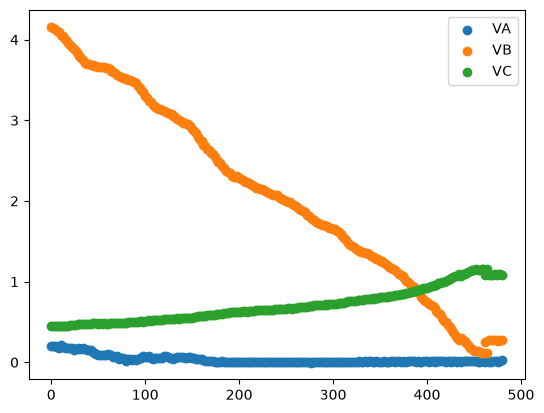

In [27]:

plt.scatter(iso_df["Time(s)"], iso_df["VA"], label="VA") #Temp 
plt.scatter(iso_df["Time(s)"], iso_df["VB"], label="VB")
plt.scatter(iso_df["Time(s)"], iso_df["VC"], label="VC")

plt.legend()

plt.show()

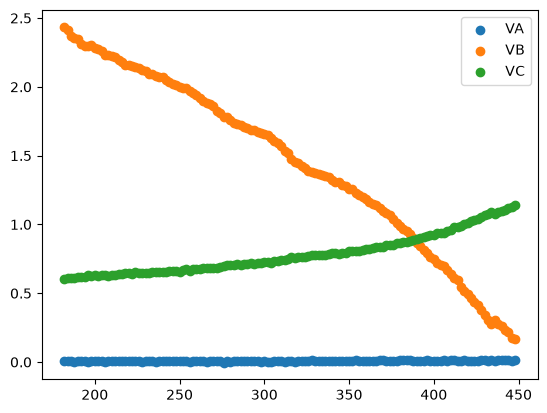

In [37]:
iso_range_T_start = 180
iso_range_T_end = 450

iso_cut_df = iso_df[(iso_df["Time(s)"] > iso_range_T_start) & (iso_df["Time(s)"] < iso_range_T_end)]

plt.scatter(iso_cut_df["Time(s)"], iso_cut_df["VA"], label="VA") #Temp 
plt.scatter(iso_cut_df["Time(s)"], iso_cut_df["VB"], label="VB")
plt.scatter(iso_cut_df["Time(s)"], iso_cut_df["VC"], label="VC")

plt.legend()

plt.show()

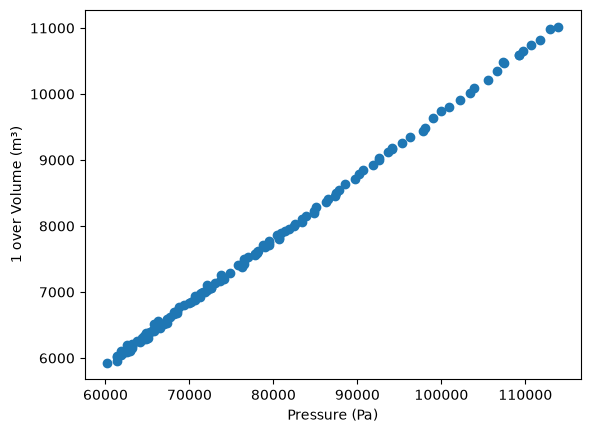

In [42]:
iso_cut_df["T"] = iso_cut_df["VA"].apply(V_to_K)
iso_cut_df["Vol"] = iso_cut_df["VB"].apply(V_to_Vol)
iso_cut_df["P"] = iso_cut_df["VC"].apply(V_to_P)

plt.scatter(iso_cut_df["P"], 1/iso_cut_df["Vol"])

plt.xlabel("Pressure (Pa)")
plt.ylabel("1 over Volume (m³)")

plt.show()


In [45]:
#Adiabatic

abd_df = pd.read_csv('Adiabatic_data.csv', skiprows=0).iloc[:,1:]

print(abd_df)

      Time(s)     VA     VB     VC
0       0.000  0.004  0.415  1.036
1       0.005  0.004  0.415  1.035
2       0.010  0.004  0.414  1.036
3       0.015  0.004  0.415  1.036
4       0.020  0.004  0.415  1.036
...       ...    ...    ...    ...
4795   23.975  0.004  0.423  1.035
4796   23.980  0.004  0.423  1.035
4797   23.985  0.004  0.422  1.035
4798   23.990  0.004  0.423  1.035
4799   23.995  0.004  0.423  1.034

[4800 rows x 4 columns]


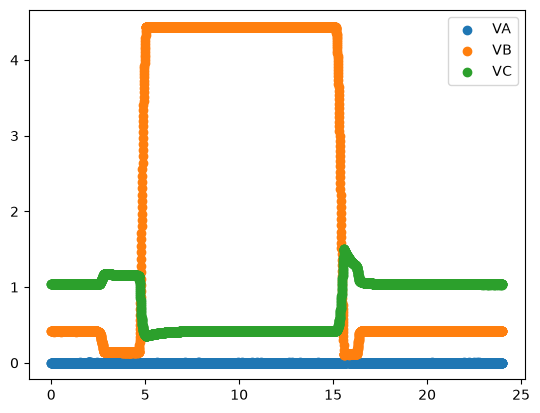

In [47]:
plt.scatter(abd_df["Time(s)"], abd_df["VA"], label="VA") #Temp 
plt.scatter(abd_df["Time(s)"], abd_df["VB"], label="VB")
plt.scatter(abd_df["Time(s)"], abd_df["VC"], label="VC")

plt.legend()

plt.show()

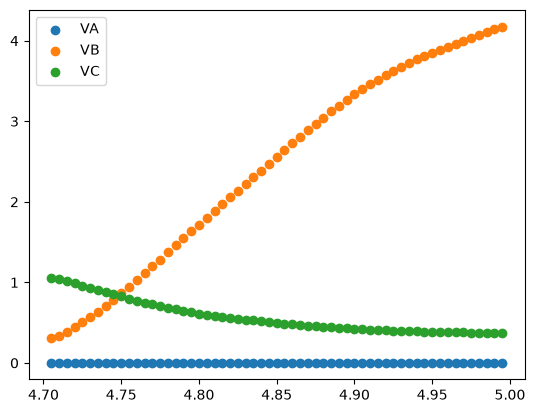

In [50]:
abd_range_T_start = 4.7
abd_range_T_end = 5

abd_df = abd_df[(abd_df["Time(s)"] > abd_range_T_start) & (abd_df["Time(s)"] < abd_range_T_end)]

plt.scatter(abd_df["Time(s)"], abd_df["VA"], label="VA") #Temp 
plt.scatter(abd_df["Time(s)"], abd_df["VB"], label="VB")
plt.scatter(abd_df["Time(s)"], abd_df["VC"], label="VC")

plt.legend()

plt.show()

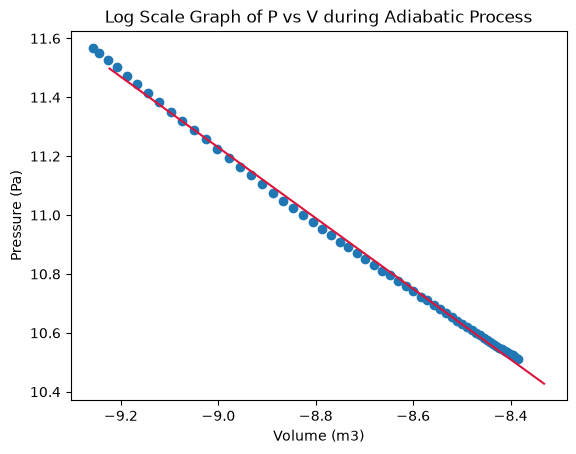

1.199 +/- 0.007


In [68]:
abd_df["T"] = abd_df["VA"].apply(V_to_K)
abd_df["Vol"] = abd_df["VB"].apply(V_to_Vol)
abd_df["P"] = abd_df["VC"].apply(V_to_P)

log_Vol = np.log(abd_df["Vol"].to_numpy())

log_P = np.log(abd_df["P"].to_numpy())

reg = stats.linregress(log_Vol, log_P)


k = np.exp(reg.intercept)
gamma = -reg.slope
err = reg.stderr

x_line = np.linspace(log_Vol.min()*0.9, log_Vol.max()*1.1)
y_line = x_line*reg.slope + reg.intercept

plt.scatter(log_Vol, log_P)
plt.plot(x_line, y_line, color="crimson")

plt.title("Log Scale Graph of P vs V during Adiabatic Process")
plt.ylabel("Pressure (Pa)")
plt.xlabel("Volume (m3)")

plt.show()

print(f"{gamma:.3f} +/- {err:.3f}")